## Preparación: cargar el código de la clase anterior

Cada notebook tiene su propia sesión: las funciones y variables de otro archivo no se comparten automáticamente. La siguiente celda ejecuta `clase_9-10.ipynb` y carga sus definiciones y valores, incluidos `s`, `modular_simbolo`, `np` y `binarios`. También ejecuta sus ejemplos y muestra sus gráficos.

Ejecutar esta celda antes del punto 3. Ambos archivos deben estar en la misma carpeta y el directorio de trabajo debe ser esa carpeta. En Colab, subir también `clase_9-10.ipynb` al directorio de trabajo de la sesión. Si se modifica la primera clase, guardar ese archivo y volver a ejecutar esta celda para actualizar sus definiciones.


Binario de 8 bits: 10110010
Vector w (menor peso primero): [0, 1, 0, 0, 1, 1, 0, 1]
s(w) = 178; esperado = 178
SF = 8; B = 125000 Hz; Ts = 0.002048 s = 2.048 ms
Comprobación correcta.
00000000 -> 0: correcto; SF = 8; Ts = 0.002048 s = 2.048 ms
01010101 -> 85: correcto; SF = 8; Ts = 0.002048 s = 2.048 ms
10110010 -> 178: correcto; SF = 8; Ts = 0.002048 s = 2.048 ms
11111111 -> 255: correcto; SF = 8; Ts = 0.002048 s = 2.048 ms
Vector de enteros: [0, 85, 178, 255]
Todas las comprobaciones fueron correctas.
Símbolo: 178; SF: 8; muestras discretas: 256; puntos por gráfico: 8193; Ts: 2.048 ms
Comprobaciones correctas. Vista temporal con sobremuestreo.


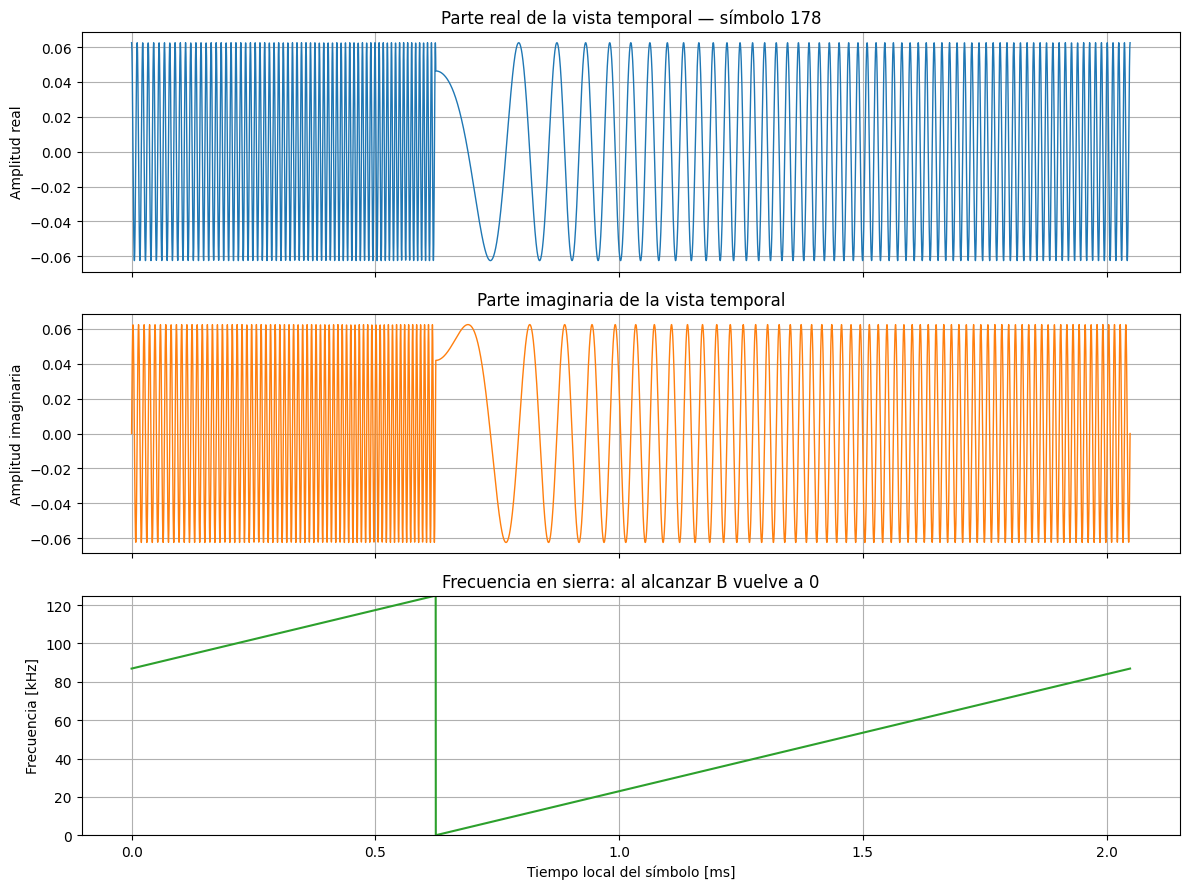

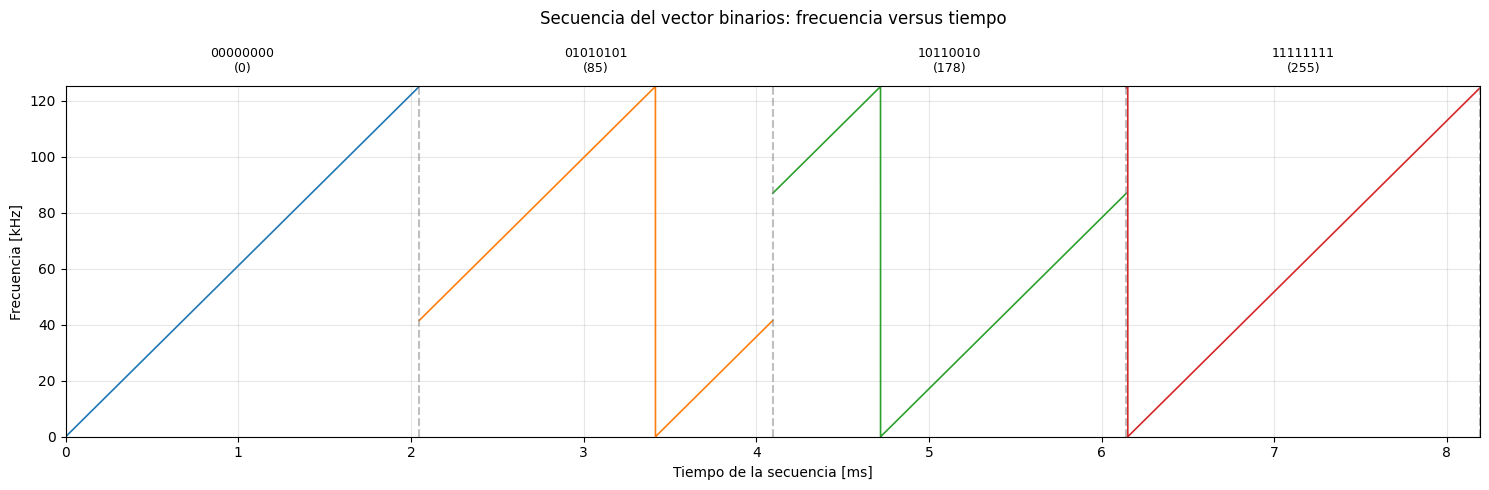

In [88]:
%run ./clase_9-10.ipynb


# Clase 16/10 — Recepción de señales LoRa

Continuación de [la clase del 9/10](clase_9-10.ipynb). En esta clase comenzamos por la recepción de la señal a través de un canal ideal.


## 3. Recepción en un canal ideal

Suponemos que la señal llega exactamente como se transmite:

$$r(nT_s+kT)=c(nT_s+kT).$$

No agregamos ruido, atenuación, retardos ni errores de frecuencia. `recibir_senal` devuelve una copia de las muestras enviadas.

Conservamos dos representaciones: `senal_recibida` es el vector completo en orden temporal y `recibidas` es una matriz con una fila por símbolo y $N=2^{SF}$ columnas. Así, `recibidas[i]` contiene las muestras del símbolo de índice `i`, como cada elemento de la lista del compañero, pero con una estructura NumPy uniforme.

Para separar las filas suponemos que conocemos $SF$ y el comienzo del primer símbolo (sincronización perfecta). Agrupar las muestras no identifica el entero transmitido: todavía no demodulamos ni recuperamos bits. Usamos las muestras discretas de `modular_simbolo`; los datos sobremuestreados se reservan para los gráficos del punto 2.


In [89]:
def recibir_senal(senal_enviada):
    """Recibe las muestras sin modificaciones a través de un canal ideal."""
    return senal_enviada.copy()


### Ejemplo: recibir la secuencia del punto 1

Convertimos los elementos de `binarios` con `s(w)`, modulamos cada entero y guardamos sus muestras en `enviadas`. Concatenamos las filas para transmitir la secuencia, simulamos el canal ideal y organizamos la recepción en `recibidas`. Comprobamos que todas las muestras y su orden se conserven.


In [90]:
B = 125_000
SF = len(binarios[0])
assert all(len(binario) == SF for binario in binarios), "Todos los símbolos deben tener el mismo SF."
N = 2 ** SF
Ts = N / B

# Convierte cada símbolo binario en su valor decimal correspondiente, invirtiendo el orden de los bits para que el bit menos significativo esté a la derecha.
valores_enviados = [s([int(bit) for bit in reversed(bits)]) for bits in binarios] 

# Una fila por símbolo; cada fila contiene N (en nuestro caso N = 256) muestras complejas. (traspuesta del array de chirps de cada símbolo)
enviadas = np.stack([
    modular_simbolo(valor, SF, B)[0] for valor in valores_enviados
])

# Secuencia temporal completa que atraviesa el canal ideal.
senal_enviada = enviadas.reshape(-1) # Vuelve a poner todas las muestras en un solo vector, concatenando los símbolos.
senal_recibida = recibir_senal(senal_enviada) # Simula la recepción de la señal a través de un canal ideal (sin modificaciones).
tiempo_recepcion = np.arange(senal_recibida.size) / B

# Organización por símbolos, suponiendo sincronización perfecta.
recibidas = senal_recibida.reshape(-1, N)
tiempo_simbolo = np.arange(N) / B

assert recibidas.shape == (len(binarios), N)
assert np.array_equal(senal_recibida, senal_enviada)
assert np.array_equal(recibidas, enviadas)
print(f"Símbolos recibidos: {recibidas.shape[0]}")
print(f"Muestras por símbolo: {recibidas.shape[1]}")
print(f"Muestras totales: {senal_recibida.size}")
print(f"Duración de la secuencia: {recibidas.shape[0] * Ts * 1000:.3f} ms")
print("Canal ideal: todas las muestras recibidas coinciden con las enviadas.")


Símbolos recibidos: 4
Muestras por símbolo: 256
Muestras totales: 1024
Duración de la secuencia: 8.192 ms
Canal ideal: todas las muestras recibidas coinciden con las enviadas.


## 4. Dechirping: multiplicar la señal recibida por un downchirp

Según la sección III del PDF, multiplicamos muestra a muestra cada símbolo recibido por:

$$\mathrm{downchirp}[k]=e^{-j2\pi k^2/N},\qquad k=0,\ldots,N-1.$$

El resultado es la señal $d$ del artículo:

$$d(nTs+kT)=r(nTs+kT)\,e^{-j2\pi k^2/N}.$$

El índice $n$ identifica el símbolo y $k$ la muestra dentro de él. El mismo downchirp se aplica desde $k=0$ en cada fila de `recibidas`. 

En el canal ideal, para el **entero transmitido $m$**, se cancela el término cuadrático:

$$d(nTs+kT)=\frac{1}{\sqrt{N}}e^{j2\pi mk/N}.$$

Así obtenemos un tono por símbolo. Su frecuencia discreta es $m/N$ ciclos por muestra, equivalente a $mB/N$ Hz módulo $B$. El símbolo cero produce una señal constante. En este punto solo hacemos la multiplicación; la identificación de los símbolos se realizará después.


In [91]:
def aplicar_dechirp(r):

    """Aplica el downchirp a un vector o a cada fila de una matriz."""
    
    r = np.asarray(r, dtype=complex)        # Convierte la entrada a un array de tipo complejo

    if r.ndim not in (1, 2) or r.size == 0:     # Verifica que la entrada sea un vector o una matriz no vacía
        raise ValueError("r debe ser un vector o una matriz no vacía de muestras.")

    N = r.shape[-1]     # si es un array, N es el tamaño del array y si es una matriz, N es el número de columnas
    
    k = np.arange(N)    # k = [0, 1, 2, ..., N-1], indices de las muestras

    downchirp = np.exp(-1j * 2 * np.pi * k ** 2 / N)    # Definimos el downchirp
    
    d = r * downchirp   # Aplicamos el downchirp a cada muestra de r

    return d, downchirp


### Ejemplo: aplicar el downchirp a los símbolos recibidos

Usamos directamente `recibidas` del punto 3. La matriz `d` conserva una fila por símbolo y el mismo número de muestras. Para comprobar el resultado, lo comparamos con los tonos teóricos calculados con los valores enviados; esos valores se usan solo para verificar, no como entrada de `aplicar_dechirp`.

Los gráficos muestran las partes real e imaginaria de `d`, usando las muestras originales. Las frecuencias altas pueden verse poco definidas al unir puntos; aquí no generamos una vista sobremuestreada.


Dechirping correcto: cada fila de d es el tono esperado.


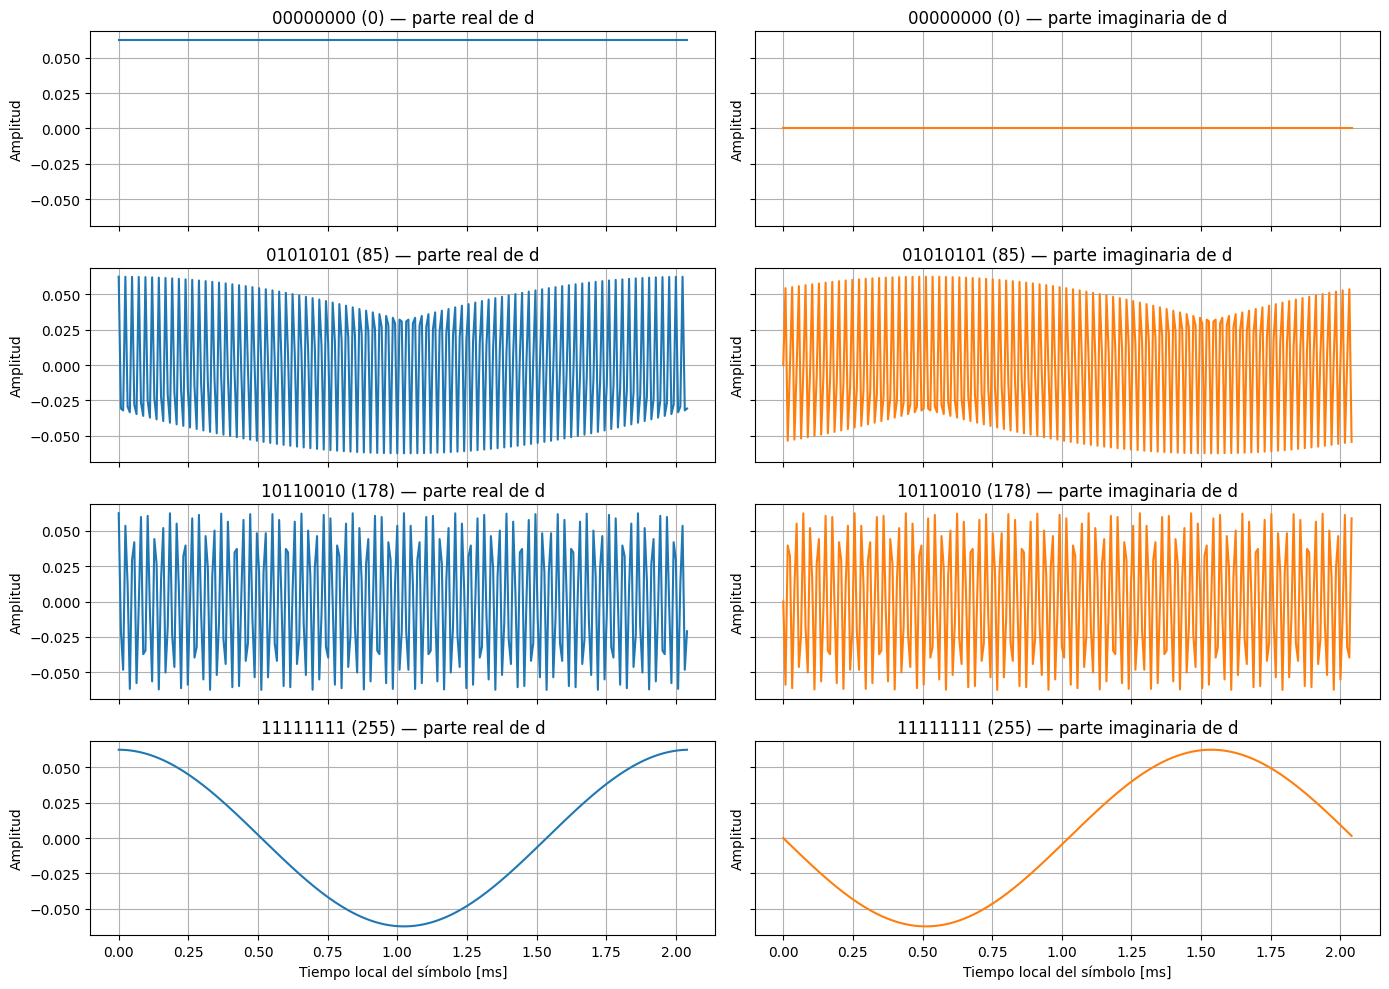

In [92]:
d, downchirp = aplicar_dechirp(recibidas)
k = np.arange(N)
tonos_esperados = np.exp(
    1j * 2 * np.pi * np.asarray(valores_enviados)[:, None] * k / N
) / np.sqrt(N)

assert d.shape == recibidas.shape
assert np.allclose(np.abs(downchirp), 1)
assert np.allclose(d, tonos_esperados)
assert np.allclose(np.abs(d), np.abs(recibidas))
print("Dechirping correcto: cada fila de d es el tono esperado.")

fig_dechirp, ejes = plt.subplots(
    len(binarios), 2, figsize=(14, 2.5 * len(binarios)),
    sharex=True, sharey=True, squeeze=False
)
for i, (bits, valor) in enumerate(zip(binarios, valores_enviados)):
    ejes[i, 0].plot(tiempo_simbolo * 1000, d[i].real)
    ejes[i, 1].plot(tiempo_simbolo * 1000, d[i].imag, color="tab:orange")
    ejes[i, 0].set_title(f"{bits} ({valor}) — parte real de d")
    ejes[i, 1].set_title(f"{bits} ({valor}) — parte imaginaria de d")
    for eje in ejes[i]:
        eje.set_ylabel("Amplitud")
        eje.grid(True)
for eje in ejes[-1]:
    eje.set_xlabel("Tiempo local del símbolo [ms]")
fig_dechirp.tight_layout()
plt.show()


## 5. FFT para calcular los productos internos de la ecuación (15)

Después del dechirping, el producto interno de la señal recibida con el chirp candidato de índice $p$ se escribe como:

$$\left\langle r(nTs+kT),c_p(nTs+kT)|_{s(nTs)=p} \right\rangle
=\frac{1}{\sqrt{N}}\sum_{k=0}^{N-1}d(nTs+kT)e^{-j2\pi pk/N}.$$

Esta es la expresión de las ecuaciones (15)-(16) del PDF: una DFT de `d` multiplicada por $1/\sqrt{N}$. Primero calculamos la FFT sin normalizar con `resultado_fft = np.fft.fft(d, axis=-1)`. Luego aplicamos el factor de forma visible: `productos_punto = resultado_fft / np.sqrt(N)`.

Si `d` es una matriz, se transforma cada fila de forma independiente. La salida conserva su forma: cada fila corresponde a un símbolo recibido y cada columna al candidato $p=0,\ldots,N-1$. Los productos internos son complejos; para visualizar su intensidad usamos $|P[p]|^2$. Conservamos el orden original de la FFT, sin `fftshift`, para que la columna coincida directamente con el índice $p$ del PDF.


In [93]:
def aplicar_fft(d):

    """Calcula los productos internos del PDF a partir del dechirping."""
    
    d = np.asarray(d, dtype=complex)        # Convierte la entrada a un array de tipo complejo
    
    if d.ndim not in (1, 2) or d.size == 0:
        raise ValueError("d debe ser un vector o una matriz no vacía de muestras.")

    N = d.shape[-1]     # si es un array, N es el tamaño del array y si es una matriz, N es el número de columnas
    
    resultado_fft = np.fft.fft(d, axis=-1)              # Calcula la FFT a lo largo del eje de las muestras (último eje)
    productos_punto = resultado_fft / np.sqrt(N)        # Normaliza la FFT dividiendo por la raíz cuadrada de N

    return productos_punto


### Ejemplo: productos internos para los símbolos recibidos

Usamos `d` del punto 4. Para verificar la función, calculamos también los productos internos directamente con todos los chirps candidatos. Ese cálculo directo es solo una comprobación: la implementación del receptor usa la FFT.

En este canal ideal, los chirps están normalizados y son ortogonales: el producto con el símbolo enviado vale 1 y los demás valen 0, salvo pequeños errores numéricos. Mostramos un gráfico por símbolo sin agregar todavía una función de decisión ni conversión a bits.


FFT normalizada: coincide con los productos internos calculados directamente.


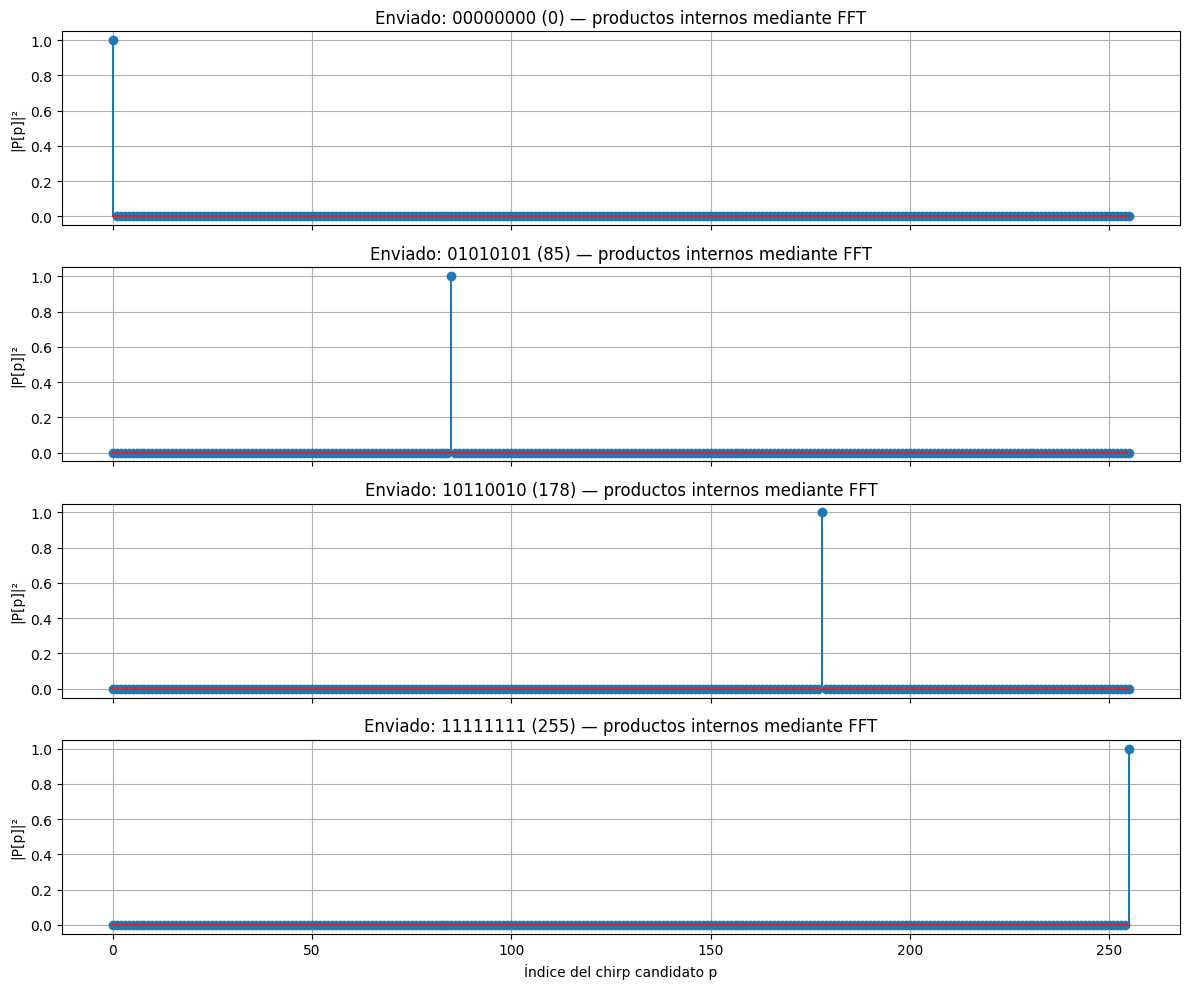

In [94]:
productos_punto = aplicar_fft(d)

# Verificación directa: suma de r[k] por el conjugado de cada candidato.
N = recibidas.shape[1]
k = np.arange(N)
p = np.arange(N)[:, None]
chirps_candidatos = np.exp(
    1j * 2 * np.pi * ((p + k) % N) * k / N
) / np.sqrt(N)
productos_directos = recibidas @ np.conj(chirps_candidatos).T

assert productos_punto.shape == recibidas.shape
assert np.allclose(productos_punto, productos_directos, atol=1e-10)
assert np.allclose(aplicar_fft(d[0]), productos_punto[0])

esperados = np.zeros_like(productos_punto)
esperados[np.arange(len(valores_enviados)), valores_enviados] = 1
assert np.allclose(productos_punto, esperados, atol=1e-10)
print("FFT normalizada: coincide con los productos internos calculados directamente.")

fig_fft, ejes_fft = plt.subplots(
    len(binarios), 1, figsize=(12, 2.5 * len(binarios)),
    sharex=True, sharey=True, squeeze=False
)
for i, (bits, valor) in enumerate(zip(binarios, valores_enviados)):
    eje = ejes_fft[i, 0]
    eje.stem(np.arange(N), np.abs(productos_punto[i]) ** 2)
    eje.set_title(f"Enviado: {bits} ({valor}) — productos internos mediante FFT")
    eje.set_ylabel("|P[p]|²")
    eje.grid(True)
ejes_fft[-1, 0].set_xlabel("Índice del chirp candidato p")
fig_fft.tight_layout()
plt.show()


## 6. Identificar el símbolo recibido

Elegimos el candidato cuyo producto interno tenga mayor módulo al cuadrado:

$$\hat{s}=\underset{p\in\{0,\ldots,N-1\}}{\operatorname{arg\,max}}\;|P[p]|^2.$$

La FFT contiene valores complejos: calculamos `np.abs(productos_punto) ** 2` para compararlos. `np.argmax` devuelve el **índice** del máximo, que es el entero estimado $\hat{s}$, no la altura del pico. Como mantuvimos la FFT sin `fftshift`, los índices ya corresponden a los símbolos $0,\ldots,N-1$.

Para una matriz aplicamos la búsqueda por fila (`axis=-1`), obteniendo una decisión por símbolo recibido. La función solo recibe los productos internos; no utiliza los valores enviados para decidir.


In [95]:
def identificar_simbolo(productos_punto):
    """Devuelve el índice de mayor módulo al cuadrado, por símbolo."""
    productos_punto = np.asarray(productos_punto, dtype=complex)
    if productos_punto.ndim not in (1, 2) or productos_punto.size == 0:
        raise ValueError("La entrada debe ser un vector o una matriz no vacía.")

    modulos_cuadrados = np.abs(productos_punto) ** 2
    simbolos_estimados = np.argmax(modulos_cuadrados, axis=-1)
    return simbolos_estimados


### Ejemplo: identificar los símbolos de la secuencia

Aplicamos la decisión a `productos_punto` del punto 5 y comparamos los enteros estimados con `valores_enviados`. Esta comparación comprueba el receptor en el canal ideal; todavía conservamos las decisiones como enteros.


In [96]:
simbolos_estimados = identificar_simbolo(productos_punto)

for i, (enviado, estimado) in enumerate(zip(valores_enviados, simbolos_estimados)):
    print(f"Símbolo {i}: enviado = {enviado}; estimado = {estimado}")

errores_simbolo = np.count_nonzero(simbolos_estimados != np.asarray(valores_enviados))
assert np.array_equal(simbolos_estimados, valores_enviados)
print("Secuencia estimada:", simbolos_estimados)
print(f"Errores de símbolo: {errores_simbolo}")


Símbolo 0: enviado = 0; estimado = 0
Símbolo 1: enviado = 85; estimado = 85
Símbolo 2: enviado = 178; estimado = 178
Símbolo 3: enviado = 255; estimado = 255
Secuencia estimada: [  0  85 178 255]
Errores de símbolo: 0


## 7. BER: proporción de bits errados

Comparamos los bits enviados y recibidos, en el mismo orden:

$$\widehat{P}_e=\mathrm{BER}_{\mathrm{medido}}=\frac{\text{bits errados}}{\text{bits totales}}.$$

Esta proporción es una estimación experimental de la probabilidad de error de bit. Un BER de 0 significa que no hubo errores en los bits observados; no demuestra por sí solo que la probabilidad teórica de error sea cero. No confundimos los errores de bits con los de símbolos: un símbolo incorrecto puede tener uno o varios bits incorrectos.

`calcular_ber` recibe dos vectores de bits (listas o arreglos de ceros y unos), de igual longitud y no vacíos. Devuelve un número entre 0 y 1. La validación se mantiene en una función auxiliar para dejar visible el cálculo.


In [97]:
def validar_bits_ber(bits_enviados, bits_recibidos):
    """Comprueba que los vectores permitan una comparación bit a bit."""
    if bits_enviados.ndim != 1 or bits_recibidos.ndim != 1:
        raise ValueError("Los bits deben estar en vectores de una dimensión.")
    if bits_enviados.size == 0 or bits_enviados.shape != bits_recibidos.shape:
        raise ValueError("Los vectores deben ser no vacíos y tener igual longitud.")
    if not (np.all(np.isin(bits_enviados, [0, 1])) and
            np.all(np.isin(bits_recibidos, [0, 1]))):
        raise ValueError("Cada bit debe ser 0 o 1.")


In [98]:
def calcular_ber(bits_enviados, bits_recibidos):
    """Devuelve la proporción de bits recibidos incorrectamente."""
    bits_enviados = np.asarray(bits_enviados)
    bits_recibidos = np.asarray(bits_recibidos)
    validar_bits_ber(bits_enviados, bits_recibidos)

    bits_errados = np.count_nonzero(bits_enviados != bits_recibidos)
    bits_totales = bits_enviados.size
    ber = bits_errados / bits_totales
    return ber


### Ejemplo 1: BER de la recepción ideal

Convertimos los enteros estimados a cadenas binarias de exactamente `SF` bits, conservando los ceros iniciales. Tanto los enviados como los recibidos se concatenan en el orden habitual de escritura, del bit de mayor peso al de menor peso. Con esta misma convención en ambos vectores podemos comparar posición por posición.


In [99]:
binarios_recibidos = [format(int(simbolo), f"0{SF}b") for simbolo in simbolos_estimados]
bits_enviados = np.array([int(bit) for bits in binarios for bit in bits])
bits_recibidos = np.array([int(bit) for bits in binarios_recibidos for bit in bits])

ber = calcular_ber(bits_enviados, bits_recibidos)
print("Binarios enviados:", binarios)
print("Binarios recibidos:", binarios_recibidos)
print(f"Bits errados: {np.count_nonzero(bits_enviados != bits_recibidos)} / {bits_enviados.size}")
print(f"BER = {ber:.6f} ({ber:.2%})")
assert ber == 0


Binarios enviados: ['00000000', '01010101', '10110010', '11111111']
Binarios recibidos: ['00000000', '01010101', '10110010', '11111111']
Bits errados: 0 / 32
BER = 0.000000 (0.00%)


### Ejemplo 2: comprobación con errores conocidos

Para comprobar la función usamos dos vectores de 8 bits con dos diferencias. El resultado debe ser $2/8=0.25$, equivalente al 25 %. Esta prueba es independiente de la recepción ideal anterior.


In [100]:
enviados_prueba = [1, 0, 1, 1, 0, 0, 1, 0]
recibidos_prueba = [1, 1, 1, 1, 0, 0, 0, 0]
ber_prueba = calcular_ber(enviados_prueba, recibidos_prueba)
assert ber_prueba == 2 / 8
print(f"BER de prueba = {ber_prueba:.2f} ({ber_prueba:.0%})")


BER de prueba = 0.25 (25%)


## 8. Canal con ruido gaussiano aditivo

La señal recibida ahora es la señal enviada más ruido:

$$r[k]=c[k]+w[k],\qquad E\{w[k]\}=0,\qquad E\{|w[k]|^2\}=\sigma^2.$$

Para media cero, la potencia media del ruido es igual a su varianza. El parámetro `sigma2` representa directamente esa potencia/varianza, no la desviación estándar.

Como nuestras muestras son complejas en banda base, generamos ruido gaussiano complejo con componentes independientes:

$$w=w_I+jw_Q,\qquad w_I,w_Q\sim\mathcal{N}(0,\sigma^2/2).$$

Cada componente tiene desviación estándar $\sqrt{\sigma^2/2}$, y sus potencias se suman: $E\{|w|^2\}=\sigma^2/2+\sigma^2/2=\sigma^2$. Si la entrada es real, la función genera ruido real de distribución $\mathcal{N}(0,\sigma^2)$, con desviación estándar $\sqrt{\sigma^2}$.

La igualdad entre potencia y varianza es teórica (media poblacional cero). En una realización finita, `np.mean(abs(ruido)**2)` y `np.var(ruido)` serán aproximaciones: la media muestral no es exactamente cero. No forzamos la media ni reescalamos las muestras, para conservar la generación gaussiana independiente.

La función devuelve `senal_con_ruido, ruido`. La semilla opcional permite repetir la misma realización sin cambiar el generador global.


In [101]:
def validar_parametros_ruido(senal, sigma2):
    """Valida las muestras y la potencia de ruido solicitada."""
    if senal.ndim not in (1, 2) or senal.size == 0:
        raise ValueError("La señal debe ser un vector o una matriz no vacía.")
    if not np.issubdtype(senal.dtype, np.number) or not np.all(np.isfinite(senal)):
        raise ValueError("La señal debe contener muestras numéricas finitas.")
    if not np.isscalar(sigma2) or not np.isrealobj(sigma2):
        raise ValueError("sigma2 debe ser un número real no negativo.")
    if not np.isfinite(sigma2) or sigma2 < 0:
        raise ValueError("sigma2 debe ser finito y no negativo.")


In [102]:
def agregar_ruido_gaussiano(senal, sigma2, semilla=None):

    """Suma ruido de media cero y potencia teórica sigma2 a la señal."""
    
    senal = np.asarray(senal)
    validar_parametros_ruido(senal, sigma2)
    generador = np.random.default_rng(semilla)  # Crea un generador de números aleatorios con la semilla proporcionada
                                                # La semilla es nula por defecto, lo que significa que se generará una 
                                                # secuencia diferente de números aleatorios cada vez que se ejecute el código.

    # Si la señal es compleja, el ruido se genera para ambas componentes (real e imaginaria) 
    # con desviación estándar ajustada.
    if np.iscomplexobj(senal):
        desviacion = np.sqrt(sigma2 / 2)                                        # La desviación estándar para cada componente (real e imaginaria) es la raíz cuadrada de la mitad de la potencia total
        ruido_real = generador.normal(0, desviacion, size=senal.shape)          # Genera ruido gaussiano para la parte real parametros: media, deviación estándar, tamaño de la muestra
        ruido_imaginario = generador.normal(0, desviacion, size=senal.shape)    # Genera ruido gaussiano para la parte imaginaria
        ruido = ruido_real + 1j * ruido_imaginario
    # Si la señal es real, se genera solo ruido real
    # la desviación estándar es la raíz cuadrada de la potencia total
    else:   
        desviacion = np.sqrt(sigma2)
        ruido = generador.normal(0, desviacion, size=senal.shape)

    senal_con_ruido = senal + ruido         # Se conforma la señal ruidosa
    return senal_con_ruido, ruido


### Ejemplo: agregar ruido a la secuencia enviada

Usamos `senal_enviada` del punto 3. `SIGMA2` es modificable; con cero se recupera el canal ideal. Mostramos la media, la varianza y la potencia medidas del ruido. La potencia se calcula con el módulo al cuadrado, ya que las muestras son complejas.


In [103]:
SIGMA2 = 0.01
SEMILLA = 42

senal_recibida_ruidosa, ruido = agregar_ruido_gaussiano(
    senal_enviada, SIGMA2, semilla=SEMILLA
)

media_ruido = np.mean(ruido)
varianza_ruido = np.var(ruido)
potencia_ruido = np.mean(np.abs(ruido) ** 2)

print(f"Potencia/varianza teórica: {SIGMA2}")
print(f"Media medida: {media_ruido}")
print(f"Varianza medida: {varianza_ruido:.6f}")
print(f"Potencia medida: {potencia_ruido:.6f}")
assert np.allclose(senal_recibida_ruidosa, senal_enviada + ruido)
assert np.isclose(potencia_ruido, varianza_ruido + np.abs(media_ruido) ** 2)


Potencia/varianza teórica: 0.01
Media medida: (-0.002068736840596871-0.0055022981646070555j)
Varianza medida: 0.010003
Potencia medida: 0.010037


### Comparación sin ruido y con ruido: vista de `fase_sierra`

Construimos una vista del símbolo elegido con `fase_sierra`, usando 32 puntos por intervalo original. Multiplicamos los ciclos acumulados por 2π y generamos la señal compleja. Luego le sumamos ruido mediante `agregar_ruido_gaussiano`, con la misma potencia `SIGMA2` del ejemplo.

`INDICE_SIMBOLO_RUIDO` elige el símbolo y `FACTOR_VISTA_RUIDO` el detalle temporal. Esta vista tiene su propia realización de ruido: no es una interpolación de la recepción discreta ni se usa para calcular el BER. Se conserva la misma varianza total por muestra visual; esto es una ilustración, no un modelo de sobremuestreo físico del ruido.


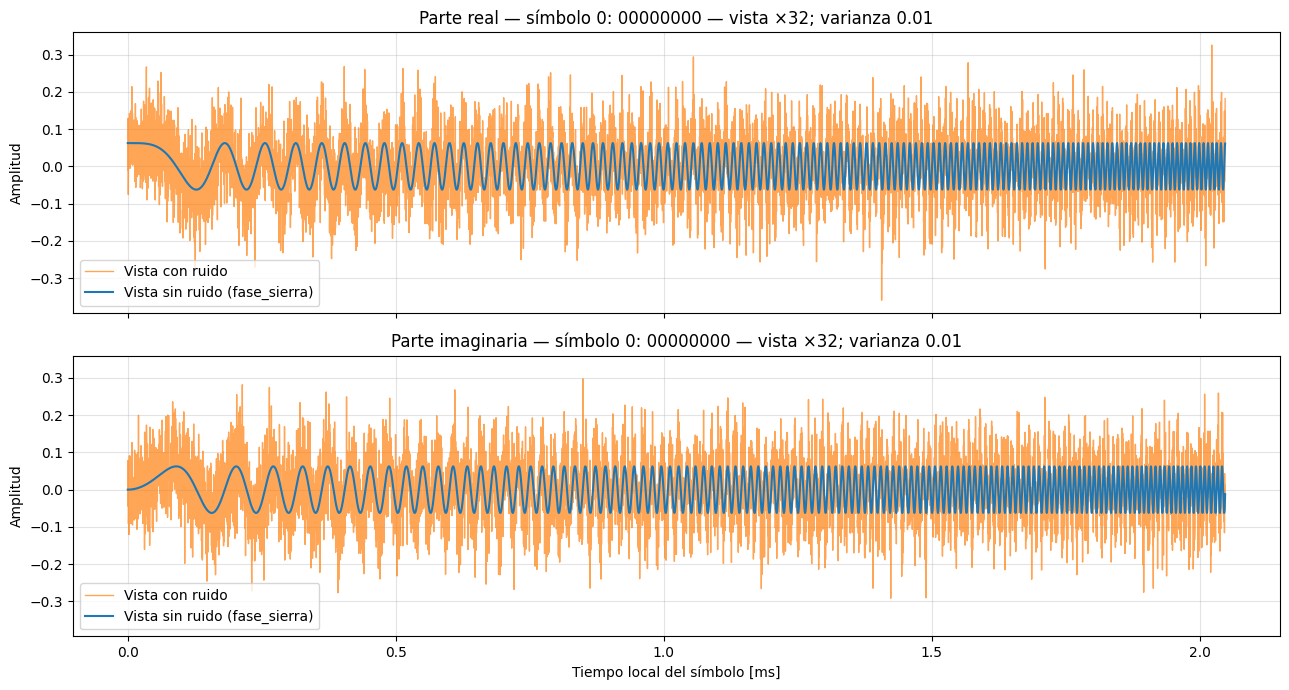

In [104]:
INDICE_SIMBOLO_RUIDO = 0
FACTOR_VISTA_RUIDO = 32
if not 0 <= INDICE_SIMBOLO_RUIDO < len(binarios):
    raise ValueError("El índice debe corresponder a un símbolo de binarios.")

bits_vista = binarios[INDICE_SIMBOLO_RUIDO]
valor_vista = s([int(bit) for bit in reversed(bits_vista)])
N_vista_ruido = 2 ** len(bits_vista)
tiempo_vista_ruido = np.arange(N_vista_ruido * FACTOR_VISTA_RUIDO) / (B * FACTOR_VISTA_RUIDO)
fase_vista_ruido = 2 * np.pi * fase_sierra(tiempo_vista_ruido, valor_vista, N_vista_ruido, B)
limpia_comparacion = np.exp(1j * fase_vista_ruido) / np.sqrt(N_vista_ruido)
ruidosa_comparacion, ruido_vista = agregar_ruido_gaussiano(
    limpia_comparacion, SIGMA2, semilla=SEMILLA
)
t_ruido = tiempo_vista_ruido * 1000

fig_comparacion_ruido, ejes_ruido = plt.subplots(2, 1, figsize=(13, 7), sharex=True, sharey=True)
for eje, parte, nombre in zip(ejes_ruido, ("real", "imag"), ("real", "imaginaria")):
    eje.plot(t_ruido, getattr(ruidosa_comparacion, parte),
             color="tab:orange", alpha=0.7, linewidth=1, label="Vista con ruido")
    eje.plot(t_ruido, getattr(limpia_comparacion, parte),
             color="tab:blue", linewidth=1.5, label="Vista sin ruido (fase_sierra)")
    eje.set_title(f"Parte {nombre} — símbolo {INDICE_SIMBOLO_RUIDO}: "
                  f"{binarios[INDICE_SIMBOLO_RUIDO]} — vista ×{FACTOR_VISTA_RUIDO}; varianza {SIGMA2:g}")
    eje.set_ylabel("Amplitud")
    eje.grid(True, alpha=0.35)
    eje.legend()
ejes_ruido[-1].set_xlabel("Tiempo local del símbolo [ms]")
fig_comparacion_ruido.tight_layout()
plt.show()


### Continuar la cadena con la señal ruidosa

Reutilizamos las funciones de dechirping, FFT, decisión y BER. Conservamos variables separadas para comparar con el canal ideal. Mantenemos sincronización perfecta y conocimiento de $SF$. El BER depende de la potencia elegida, de la realización de ruido y de cuántos bits se transmiten; una realización corta puede tener cero errores aun con ruido.


In [105]:
recibidas_ruidosas = senal_recibida_ruidosa.reshape(-1, N)
d_ruidosa, _ = aplicar_dechirp(recibidas_ruidosas)
productos_ruidosos = aplicar_fft(d_ruidosa)
simbolos_estimados_ruidosos = identificar_simbolo(productos_ruidosos)
binarios_recibidos_ruidosos = [
    format(int(simbolo), f"0{SF}b") for simbolo in simbolos_estimados_ruidosos
]
bits_recibidos_ruidosos = np.array([
    int(bit) for bits in binarios_recibidos_ruidosos for bit in bits
])
ber_ruidoso = calcular_ber(bits_enviados, bits_recibidos_ruidosos)

print("Binarios enviados:", binarios)
print("Binarios recibidos con ruido:", binarios_recibidos_ruidosos)
print(f"BER con ruido = {ber_ruidoso:.6f} ({ber_ruidoso:.2%})")


Binarios enviados: ['00000000', '01010101', '10110010', '11111111']
Binarios recibidos con ruido: ['00000000', '01010101', '10110010', '11111111']
BER con ruido = 0.000000 (0.00%)


## 9. Parámetros del ruido a partir de una SNR objetivo

La SNR compara la potencia media de la señal con la potencia media del ruido:

$$\mathrm{SNR}_{dB}=10\log_{10}\left(\frac{P_s}{P_n}\right),\qquad
\mathrm{SNR}_{lineal}=10^{\mathrm{SNR}_{dB}/10}.$$

Calculamos la potencia de las muestras enviadas y despejamos la potencia de ruido necesaria:

$$P_s=\frac{1}{L}\sum_{k=0}^{L-1}|c[k]|^2,\qquad
P_n=\frac{P_s}{10^{\mathrm{SNR}_{dB}/10}}=\sigma^2.$$

La media del ruido sigue siendo cero. Para ruido real, la desviación estándar es $\sigma=\sqrt{\sigma^2}$. Para ruido complejo, cada componente independiente tiene desviación $\sigma_{componente}=\sqrt{\sigma^2/2}$.

`calcular_parametros_ruido` devuelve un diccionario con la potencia de señal, la SNR lineal, la media, la potencia/varianza total `sigma2`, su raíz `sigma` y la desviación por componente `sigma_componente`. Para generar ruido con la función del punto 8 se pasa **`sigma2`**, no `sigma` ni la desviación por componente.

En nuestros chirps normalizados, $\sum|c[k]|^2=1$ y $P_s=1/N$, no 1. La SNR obtenida con una realización finita será cercana al objetivo, porque su potencia de ruido medida fluctúa.


In [106]:
def validar_snr(snr_db):
    """La SNR en dB debe ser real y finita; puede ser negativa."""
    if not np.isscalar(snr_db) or not np.isrealobj(snr_db):
        raise ValueError("La SNR en dB debe ser un número real.")
    if not np.isfinite(snr_db):
        raise ValueError("La SNR en dB debe ser finita.")


In [107]:
def calcular_parametros_ruido(senal, snr_db):

    """Calcula la potencia y desviaciones del ruido para una SNR objetivo."""
    
    senal = np.asarray(senal)                           # Convierte la entrada a un array de tipo complejo
    validar_parametros_ruido(senal, 0)                  # Verifica que la señal sea un vector o matriz no vacía y que la potencia de ruido sea no negativa
    validar_snr(snr_db)                                 # Verifica que la SNR en dB sea un número real y finito

    potencia_senal = np.mean(np.abs(senal) ** 2)        # Calcula la potencia de la señal como el promedio del cuadrado de la magnitud de las muestras
    snr_lineal = 10.0 ** (float(snr_db) / 10)           # Convierte la SNR de dB a lineal
    
    if potencia_senal <= 0 or not np.isfinite(potencia_senal):
        raise ValueError("La potencia de señal debe ser positiva y finita.")
    if snr_lineal <= 0 or not np.isfinite(snr_lineal):
        raise ValueError("La SNR está fuera del rango numérico representable.")

    sigma2 = potencia_senal / snr_lineal                # Calcula la potencia de ruido necesaria para alcanzar la SNR deseada
    sigma = np.sqrt(sigma2)                             # Calcula la desviación estándar del ruido a partir de la potencia de ruido
    sigma_componente = np.sqrt(sigma2 / 2) if np.iscomplexobj(senal) else sigma     # Calcula la desviación estándar de cada componente del ruido (real e imaginaria) si la señal es compleja; si es real, es igual a sigma

    return {                                            # Devuelve un diccionario con los parámetros del ruido calculados
        "potencia_senal": potencia_senal,
        "snr_lineal": snr_lineal,
        "media": 0.0,
        "sigma2": sigma2,
        "sigma": sigma,
        "sigma_componente": sigma_componente,
    }


### Ejemplo: obtener el ruido para una SNR de diseño

Modificá `SNR_DB_OBJETIVO` y ejecutá las celdas. Calculamos los parámetros usando `senal_enviada`, generamos el ruido y comparamos la SNR medida con el objetivo. Por ejemplo, 10 dB significa que la potencia de señal es diez veces la potencia de ruido.


In [108]:
SNR_DB_OBJETIVO = 10

parametros_ruido = calcular_parametros_ruido(senal_enviada, SNR_DB_OBJETIVO)

senal_recibida_snr, ruido_snr = agregar_ruido_gaussiano(
    senal_enviada, parametros_ruido["sigma2"], semilla=42
)
potencia_ruido_medida = np.mean(np.abs(ruido_snr) ** 2)
snr_db_medida = 10 * np.log10(
    parametros_ruido["potencia_senal"] / potencia_ruido_medida
)

print(f"Potencia de señal: {parametros_ruido['potencia_senal']:.8f}")
print(f"Potencia/varianza de ruido requerida: {parametros_ruido['sigma2']:.8f}")
print(f"Desviación por componente: {parametros_ruido['sigma_componente']:.8f}")
print(f"SNR objetivo: {SNR_DB_OBJETIVO:.2f} dB")
print(f"SNR medida: {snr_db_medida:.2f} dB")

snr_db_calculada = 10 * np.log10(
    parametros_ruido["potencia_senal"] / parametros_ruido["sigma2"]
)
assert np.isclose(snr_db_calculada, SNR_DB_OBJETIVO)


Potencia de señal: 0.00390625
Potencia/varianza de ruido requerida: 0.00039063
Desviación por componente: 0.01397542
SNR objetivo: 10.00 dB
SNR medida: 9.98 dB


### Recibir y calcular el BER para la SNR elegida

La señal generada con la SNR objetivo continúa por las mismas funciones del receptor. La sincronización se mantiene perfecta. El BER mostrado corresponde a esta secuencia y realización de ruido.


In [109]:
recibidas_snr = senal_recibida_snr.reshape(-1, N)
d_snr, _ = aplicar_dechirp(recibidas_snr)
productos_snr = aplicar_fft(d_snr)
simbolos_estimados_snr = identificar_simbolo(productos_snr)
binarios_recibidos_snr = [format(int(valor), f"0{SF}b") for valor in simbolos_estimados_snr]
bits_recibidos_snr = np.array([int(bit) for bits in binarios_recibidos_snr for bit in bits])
ber_snr = calcular_ber(bits_enviados, bits_recibidos_snr)
print("Binarios recibidos:", binarios_recibidos_snr)
print(f"BER para SNR objetivo de {SNR_DB_OBJETIVO:.2f} dB: {ber_snr:.6f}")


Binarios recibidos: ['00000000', '01010101', '10110010', '11111111']
BER para SNR objetivo de 10.00 dB: 0.000000
